In [1]:
import xarray as xr
import os
os.chdir(r"C:\Users\Fede\OneDrive\projects\fauba\soja_precipitation_enso\scripts")
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd

from cartopy.io import shapereader


In [3]:
ds = xr.open_dataset("data/cmorph_argentina/cmorph_argentina_2024_2025.nc")
print(ds.cmorph.a)

{'dtype': dtype('float32'), 'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': True, 'complevel': 4, 'fletcher32': False, 'contiguous': False, 'chunksizes': (365, 140, 84), 'preferred_chunks': {'time': 365, 'lat': 140, 'lon': 84}, 'source': 'C:\\Users\\Fede\\OneDrive\\projects\\fauba\\soja_precipitation_enso\\scripts\\data\\cmorph_argentina\\cmorph_argentina_2024_2025.nc', 'original_shape': (9497, 140, 84), '_FillValue': np.float32(nan), 'coordinates': 'time lat lon'}


In [4]:
shpfilename = shapereader.natural_earth(
        resolution='10m',
        category='cultural',
        name='admin_1_states_provinces'
    )
reader = shapereader.Reader(shpfilename)



In [5]:
"""
march_1_10 = ds["cmorph"].sel(
    time=slice("2025-03-05", "2025-03-10")
).sum("time")
"""

'\nmarch_1_10 = ds["cmorph"].sel(\n    time=slice("2025-03-05", "2025-03-10")\n).sum("time")\n'

In [6]:
events = {
    "La Plata\n2–3 Apr 2013": ("2013-04-01", "2013-04-05"),
    "Formosa\n5–6 May 2014": ("2014-05-04", "2014-05-08"),
    "Cuenca del Plata\n20–27 Dec 2015": ("2015-12-25", "2015-12-29"),
    "Bahia Blanca- Buenos Aires\n7 Mar 2025": ("2025-03-06", "2025-03-10"),
}

event_data = {}

for name, (start, end) in events.items():
    event_data[name] = (
        ds["cmorph"]
        .sel(time=slice(start, end))
        .sum("time")
    )

In [10]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
from matplotlib.gridspec import GridSpec
# --------------------------------------------------
# Custom precipitation colormap
# --------------------------------------------------

precip_colors = [
    "white",       # 0 mm
    "lightblue",
    "blue",
    "cyan",
    "yellow",
    "orange",
    "red",
    "purple",
    "black"
]

precip_cmap = LinearSegmentedColormap.from_list(
    "precip",
    precip_colors,
    N=256
)


In [8]:
vmin = 0
vmax = 300
levels = np.linspace(vmin, 300, 21)

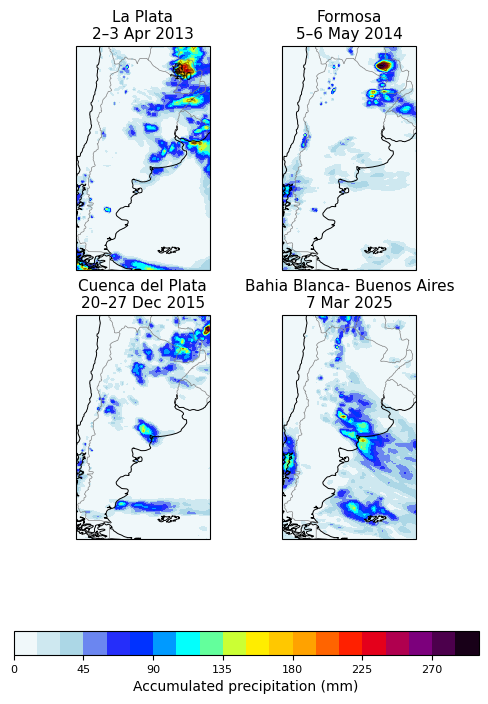

In [9]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(6, 8),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

axes = axes.ravel()

for ax, (name, toplot) in zip(axes, event_data.items()):

    cf = ax.contourf(
    toplot.lon,
    toplot.lat,
    toplot,
    levels=levels,
    cmap=precip_cmap,
    vmin=vmin,
    vmax=300,
    extend="neither",
    transform=ccrs.PlateCarree()
)

    cs = ax.contour(
        toplot.lon,
        toplot.lat,
        toplot,
        levels=np.linspace(vmax/2, vmax, 10),
        colors="black",
        linewidths=0.2,
        transform=ccrs.PlateCarree()
    )

    ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")

    ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, edgecolor="gray", linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")

    ax.set_title(name, fontsize=11, pad=5)


plt.subplots_adjust(wspace= -0.2)


# Small shared colorbar below
cbar = fig.colorbar(
    cf,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    extend="neither"
)


cbar.set_label("Accumulated precipitation (mm)", fontsize=10)
cbar.ax.tick_params(labelsize=8)



### Monthly

In [6]:
ds_clean = ds.drop_vars(["time_bounds","lat_bounds","lon_bounds"])
print(type(ds_clean.cmorph.data))
print(ds_clean.cmorph.encoding)

<class 'numpy.ndarray'>
{'dtype': dtype('float32'), 'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': True, 'complevel': 4, 'fletcher32': False, 'contiguous': False, 'chunksizes': (365, 140, 84), 'preferred_chunks': {'time': 365, 'lat': 140, 'lon': 84}, 'source': 'C:\\Users\\Fede\\OneDrive\\projects\\fauba\\soja_precipitation_enso\\scripts\\data\\cmorph_argentina\\cmorph_argentina_2024_2025.nc', 'original_shape': (9497, 140, 84), '_FillValue': np.float32(nan), 'coordinates': 'time lat lon'}


In [7]:
ds_monthly = ds_clean.resample(time="MS").sum()

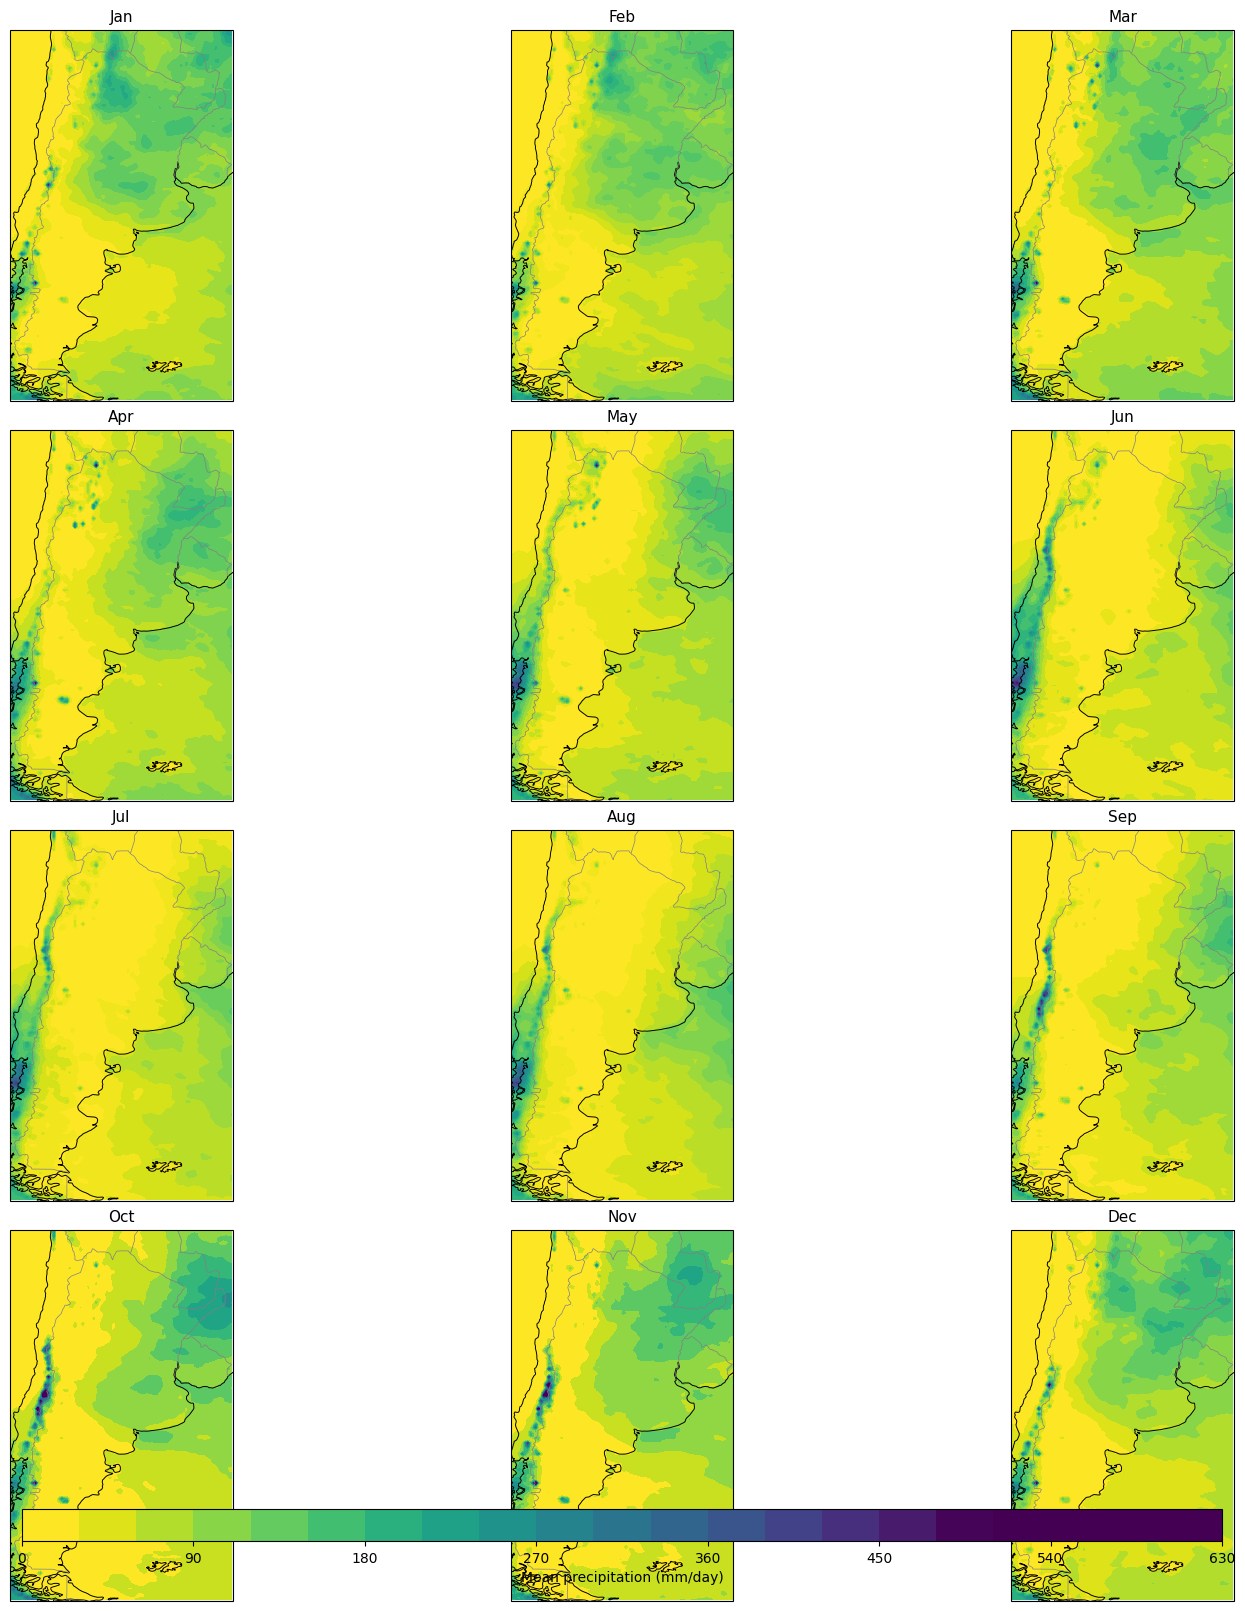

In [14]:
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Monthly climatology: mean for each calendar month across all years
monthly_climo = ds_monthly.groupby("time.month").mean("time")

# Color scale based on the full climatology
vmin = float(monthly_climo.cmorph.min().values)
vmax = float(monthly_climo.cmorph.max().values)
levels = np.linspace(vmin, vmax, 21)

fig, axes = plt.subplots(
    4,
    3,
    figsize=(15, 16),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
axes = axes.ravel()

for ax, month, month_name in zip(axes, range(1, 13), month_names):
    toplot = monthly_climo.cmorph.sel(month=month)

    cf = ax.contourf(
        toplot.lon,
        toplot.lat,
        toplot,
        levels=20,
        cmap="viridis_r",
        vmin=20,
        vmax=500,
        transform=ccrs.PlateCarree(),
    )

    ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
    ax.add_feature(cfeature.BORDERS, edgecolor="gray", linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke")
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue")
    ax.set_extent([-74, -53, -55, -20], crs=ccrs.PlateCarree())
    ax.set_title(month_name, fontsize=11)

# Hide any unused axes
for ax in axes[len(month_names):]:
    ax.set_visible(False)

cbar_ax = fig.add_axes([0.10, 0.04, 0.80, 0.02])
fig.colorbar(cf, cax=cbar_ax, orientation="horizontal")
cbar_ax.set_xlabel("Mean precipitation (mm/day)", fontsize=10)

plt.show()
